

**Dataset Source:** (https://docs.ultralytics.com/datasets/detect/medical-pills/)

In [1]:
!pip install -q ultralytics

In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from pathlib import Path
import random
import shutil
import zipfile
import yaml
import torch

print('GPU available:', torch.cuda.is_available())
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (slow)')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU available: False
Device: CPU (slow)


In [3]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/medical-pills.zip -O /content/medical-pills.zip

archive = Path('/content/medical-pills.zip')
assert archive.exists() and archive.stat().st_size > 10000, 'Download failed. Re-run this cell.'

extract_root = Path('/content/datasets')
extract_root.mkdir(exist_ok=True, parents=True)
with zipfile.ZipFile(archive) as z:
    z.extractall(extract_root)

candidates = [p.parent.parent for p in extract_root.rglob('images/train') if p.is_dir() and (p.parent.parent / 'labels/train').exists()]
assert candidates, 'Dataset folder not found after extraction. Inspect /content/datasets.'
dataset_path = candidates[0]
print('Dataset path:', dataset_path)
print('Training images:', len([p for p in (dataset_path/'images/train').iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}]))
print('Validation images:', len([p for p in (dataset_path/'images/val').iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}]))

/content/medical-pi 100%[===================>]   8.20M  --.-KB/s    in 0.08s   
Dataset path: /content/datasets
Training images: 92
Validation images: 23


In [4]:
val_images = dataset_path / 'images/val'
val_labels = dataset_path / 'labels/val'
test_images = dataset_path / 'images/test'
test_labels = dataset_path / 'labels/test'
test_images.mkdir(parents=True, exist_ok=True)
test_labels.mkdir(parents=True, exist_ok=True)
image_extensions = {'.jpg', '.jpeg', '.png', '.webp'}

# Re-running this cell does not move more images.
if not any(p.suffix.lower() in image_extensions for p in test_images.iterdir()):
    image_files = sorted(p for p in val_images.iterdir() if p.suffix.lower() in image_extensions)
    assert len(image_files) >= 4, 'Not enough validation images for test split.'
    random.seed(42)
    selected = random.sample(image_files, 3)
    for img in selected:
        label = val_labels / f'{img.stem}.txt'
        shutil.move(str(img), str(test_images / img.name))
        if label.exists():
            shutil.move(str(label), str(test_labels / label.name))

def count_imgs(folder):
    return sum(p.suffix.lower() in image_extensions for p in folder.iterdir())

print('Training:', count_imgs(dataset_path/'images/train'))
print('Validation:', count_imgs(val_images))
print('Testing:', count_imgs(test_images))
assert count_imgs(test_images) >= 3, 'Three test images required.'

Training: 92
Validation: 20
Testing: 3


In [5]:
data_config = {
    'path': str(dataset_path.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {0: 'pill'},
}
config_file = Path('/content/medical_pills_custom.yaml')
with open(config_file, 'w') as f:
    yaml.safe_dump(data_config, f, sort_keys=False)
print(config_file.read_text())

path: /content/datasets
train: images/train
val: images/val
test: images/test
names:
  0: pill



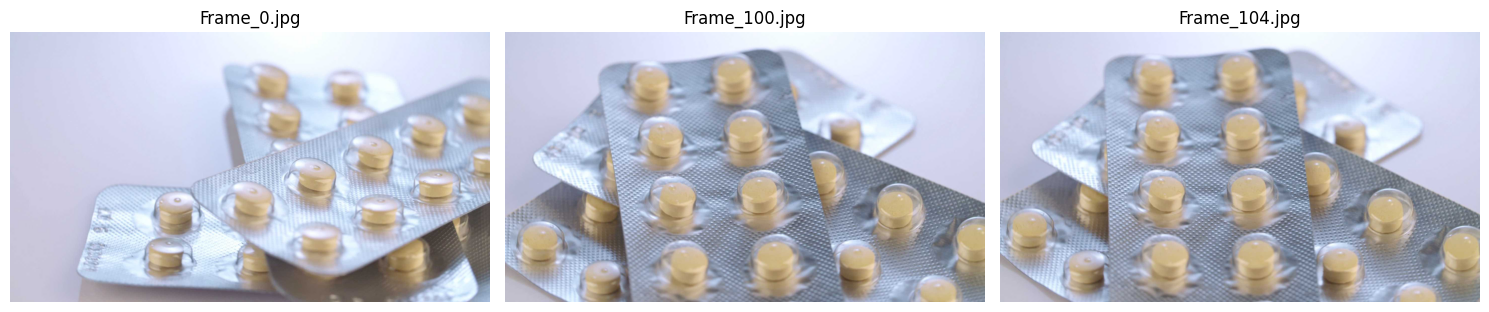

In [6]:
sample_images = sorted(p for p in (dataset_path/'images/train').iterdir() if p.suffix.lower() in image_extensions)[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img in zip(axes, sample_images):
    ax.imshow(Image.open(img).convert('RGB'))
    ax.set_title(img.name)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [7]:
model = YOLO('yolo11n.pt')
print('Number of original COCO classes:', len(model.names))
print('Selected model: YOLO11 Nano')
print('New target class: pill')

Number of original COCO classes: 80
Selected model: YOLO11 Nano
New target class: pill


In [8]:
device = 0 if torch.cuda.is_available() else 'cpu'
results = model.train(
    data=str(config_file),
    epochs=30,
    imgsz=640,
    batch=8,
    patience=30,
    device=device,
    workers=2,
    project='/content/runs/detect',
    name='medical_pills_detection',
    exist_ok=True,
    plots=True,
)
print('Training finished. Best weights saved to:', model.trainer.best)

Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/medical_pills_custom.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=medical_pills_detection, nbs=64, nms=None, opset=Non

In [9]:
best_weights = Path('/content/runs/detect/medical_pills_detection/weights/best.pt')
assert best_weights.exists(), 'best.pt is missing. Check training output.'
best_model = YOLO(str(best_weights))
print('Fine-tuned model loaded successfully!')
print('Classes:', best_model.names)

Fine-tuned model loaded successfully!
Classes: {0: 'pill'}


In [10]:
metrics = best_model.val(data=str(config_file), split='val', imgsz=640, plots=True)
print('Validation completed.')

Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1540.9±436.7 MB/s, size: 77.8 KB)
val: Scanning /content/datasets/labels/val.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 5.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.6s
                   all         20        352      0.992      0.974      0.995      0.784
Speed: 1.4ms preprocess, 109.4ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val
Validation completed.


In [11]:
precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map50_95 = metrics.box.map

print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'mAP50: {map50:.4f}')
print(f'mAP50-95: {map50_95:.4f}')

Precision: 0.9922
Recall: 0.9744
mAP50: 0.9946
mAP50-95: 0.7837



0: 384x640 20 pills, 117.0ms
1: 384x640 18 pills, 117.0ms
2: 384x640 15 pills, 117.0ms
Speed: 3.1ms preprocess, 117.0ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)


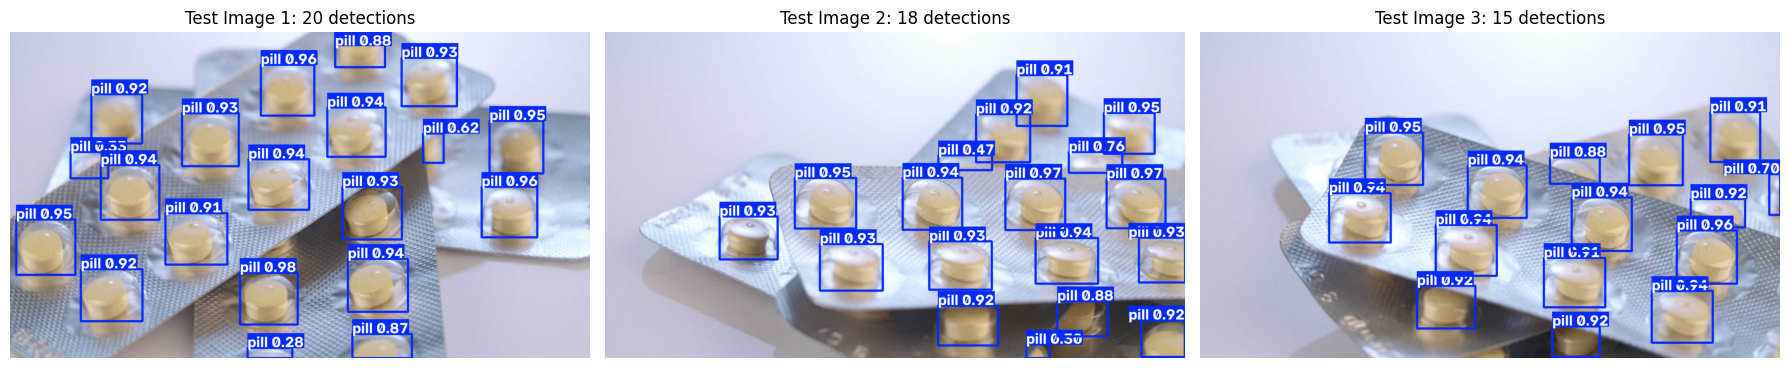

In [12]:
test_files = sorted(p for p in test_images.iterdir() if p.suffix.lower() in image_extensions)[:3]
assert len(test_files) == 3, 'Exactly three unseen test images are needed.'
test_results = best_model.predict([str(p) for p in test_files], conf=0.25, imgsz=640)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, (ax, result) in enumerate(zip(axes, test_results)):
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f'Test Image {i+1}: {len(result.boxes)} detections')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [13]:
for i, result in enumerate(test_results, start=1):
    print(f'\nTest Image {i}: {len(result.boxes)} detections')
    for j, box in enumerate(result.boxes):
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = float(box.conf[0])
        label = best_model.names[int(box.cls[0])]
        print(f' {j}: {label:10s} conf={conf:.2f} box=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})')


Test Image 1: 20 detections
 0: pill       conf=0.98 box=(761, 798, 952, 969)
 1: pill       conf=0.96 box=(830, 111, 1008, 279)
 2: pill       conf=0.96 box=(1562, 515, 1745, 682)
 3: pill       conf=0.95 box=(21, 623, 217, 806)
 4: pill       conf=0.95 box=(1587, 296, 1766, 470)
 5: pill       conf=0.94 box=(790, 423, 991, 590)
 6: pill       conf=0.94 box=(1119, 753, 1317, 927)
 7: pill       conf=0.94 box=(300, 442, 495, 623)
 8: pill       conf=0.94 box=(1050, 252, 1244, 415)
 9: pill       conf=0.93 box=(1100, 515, 1297, 688)
 10: pill       conf=0.93 box=(570, 271, 758, 447)
 11: pill       conf=0.93 box=(1296, 88, 1480, 248)
 12: pill       conf=0.92 box=(269, 209, 438, 371)
 13: pill       conf=0.92 box=(234, 786, 439, 959)
 14: pill       conf=0.91 box=(514, 601, 720, 772)
 15: pill       conf=0.88 box=(1076, 1, 1242, 119)
 16: pill       conf=0.87 box=(1133, 1001, 1330, 1080)
 17: pill       conf=0.62 box=(1367, 339, 1435, 436)
 18: pill       conf=0.33 box=(201, 400, 325, 

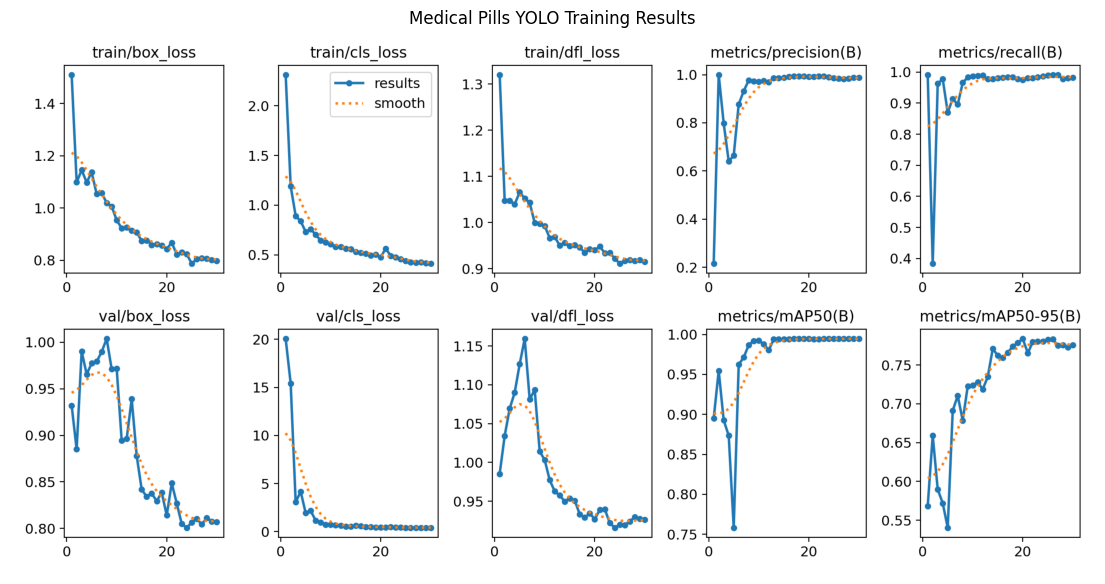

In [14]:
plot_file = Path('/content/runs/detect/medical_pills_detection/results.png')
if plot_file.exists():
    plt.figure(figsize=(14, 8))
    plt.imshow(Image.open(plot_file))
    plt.title('Medical Pills YOLO Training Results')
    plt.axis('off')
    plt.show()
else:
    print('Training plot was not saved. Check the training results folder.')

In [15]:
print('===== YOLO FINE-TUNING SUMMARY =====')
print('Dataset: Ultralytics Medical Pills')
print('Model: YOLO11 Nano')
print('Custom Class: pill')
print('Configured epochs: 30')
print('Image size: 640')
print('Batch size: 8')
print('Training images:', count_imgs(dataset_path/'images/train'))
print('Validation images:', count_imgs(dataset_path/'images/val'))
print('Unseen test images:', len(test_files))
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'mAP50: {map50:.4f}')
print(f'mAP50-95: {map50_95:.4f}')

===== YOLO FINE-TUNING SUMMARY =====
Dataset: Ultralytics Medical Pills
Model: YOLO11 Nano
Custom Class: pill
Configured epochs: 30
Image size: 640
Batch size: 8
Training images: 92
Validation images: 20
Unseen test images: 3
Precision: 0.9922
Recall: 0.9744
mAP50: 0.9946
mAP50-95: 0.7837


In [16]:
from google.colab import files
files.download(str(best_weights))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>